# 04 · Train sparse MoE and routing controls

Train the learned top-k router, a fixed random-router control, and a regime-informed oracle.

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Inspect models

Hidden widths and capacity counts are explicit. Active parameters are a proxy, not a FLOP measurement.

In [2]:
from twilight_moe.models import build_model
names = ['moe', 'random', 'oracle']
display(pd.DataFrame([{'model': name, **build_model(name, cfg).capacity()} for name in names]))
print(build_model(names[0], cfg))

,model,total_parameters,trainable_parameters,active_parameters
0,moe,7599,7599,5355
1,random,6828,6732,4584
2,oracle,6732,6732,2244


MoE(
  (experts): ModuleList(
    (0-2): 3 x Sequential(
      (0): Linear(in_features=32, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): Tanh()
      (4): Linear(in_features=32, out_features=4, bias=True)
    )
  )
  (router): Router(
    (network): Sequential(
      (0): Linear(in_features=32, out_features=24, bias=True)
      (1): Tanh()
      (2): Linear(in_features=24, out_features=3, bias=True)
    )
  )
)


## Train and select checkpoints

The selected epoch minimizes validation MSE. Test evaluation occurs after selection. Losses for training are normalized; reported test MSE is in original state units.

In [3]:
from twilight_moe.experiment import run_models
rows = run_models(cfg, names)
display(rows[['model', 'seed', 'best_epoch', 'test_mse', 'training_seconds']].round(6))

moe           seed=7 test MSE=0.011591; best epoch=37


random        seed=7 test MSE=0.011750; best epoch=40


oracle        seed=7 test MSE=0.006621; best epoch=39


moe           seed=17 test MSE=0.011479; best epoch=40


random        seed=17 test MSE=0.011870; best epoch=40


oracle        seed=17 test MSE=0.006709; best epoch=33


moe           seed=27 test MSE=0.011328; best epoch=39


random        seed=27 test MSE=0.011494; best epoch=40


oracle        seed=27 test MSE=0.006682; best epoch=35


,model,seed,best_epoch,test_mse,training_seconds
0,moe,7,37,0.011591,18.356058
1,random,7,40,0.011750,16.914474
2,oracle,7,39,0.006621,15.838182
3,moe,17,40,0.011479,18.289059
4,random,17,40,0.011870,16.735143
5,oracle,17,33,0.006709,15.787319
6,moe,27,39,0.011328,18.292265
7,random,27,40,0.011494,16.899963
8,oracle,27,35,0.006682,15.760044


## Plot validation learning curves

The first seed is shown. Each model has a separate history CSV for every seed.

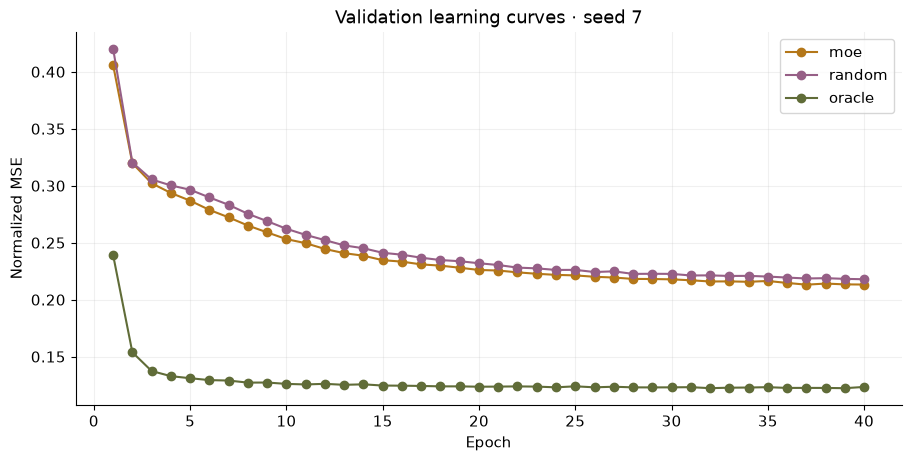

In [4]:
seed = cfg['seeds'][0]
fig, ax = plt.subplots()
for name in names:
    history = pd.read_csv(run_dir(cfg) / f'{name}_seed{seed}_history.csv')
    ax.plot(history['epoch'], history['val_mse_normalized'], marker='o',
            label=name, color=COLORS[name])
ax.set(title=f'Validation learning curves · seed {seed}', xlabel='Epoch', ylabel='Normalized MSE')
ax.legend()
save_figure(fig, cfg, 'learning_' + names[0])
plt.show()

## Interpretation

The random router is frozen and input-dependent. The oracle sees true regimes and activates one expert. A best checkpoint at the last epoch is a reason to examine training length, not proof of convergence. Do not tune repeatedly against these test errors.